# Asymmetric Duos on ImageNetV2 + dynamic gate

1. *(GPU)* Runs pretrained ImageNet models on **ImageNetV2 matched-frequency** (10,000 images) and saves their logits. No fine-tuning is needed, because the models already predict the 1,000 ImageNet classes.
2. *(CPU)* Builds the paper's Duos from the cached logits: temperature-scaled base, unweighted Duo, learned-weight Duo and UQ-only Duo. Reports Acc, NLL, AUROC, AURC and SAC@98 against FLOP balance (cf. the ImageNetV2 panels of Figs 3–6).
3. Computes the full Duo's confidence two ways: as defined in paper §3.1, and as in the released evaluator.
4. **Extension**: a per-image dynamic gate fitted with regularised NLL and compared with the static Duo on the same held-out examples, including a confidence-only ablation.

**Running:** Kaggle with a T4 GPU and Internet on (about 5 min for logits, about 25 min for the CPU analysis with 10 splits). If `LOGIT_DIR` already contains the cached logits, the GPU section is skipped.

**Setup and deviations from the paper**
- **Split:** the paper fits temperatures on ImageNet-1K validation data and treats ImageNetV2 as an OOD test set. Here ImageNet-1K is not used: ImageNetV2 is **split 50/50, stratified by class** (5 images per class each side), and this is repeated over `N_SPLITS = 10` random splits. Absolute numbers are therefore not directly comparable with the paper. The comparison between methods is.
- **Checkpoints:** ConvNeXt-B uses torchvision `IMAGENET1K_V1`. The ResNets use **timm default pretrained weights** (`resnet10t.c3_in1k`, `resnet18/50/101/152.a1_in1k`, `resnet200d.ra2_in1k`). For ResNet-18 to ResNet-152 these differ from the torchvision `IMAGENET1K_V1` weights used in the `partA` notebook.
- **Unweighted Duo** = 0.5·(TS large) + 0.5·(TS small), i.e. the average of individually temperature-scaled logits, as in the released evaluator.
- **FLOPs** are counted with fvcore at 224×224. ResNet-10T and ResNet-200D evaluate at 176 and 256 px, and both counts are logged.


In [1]:
# --- Setup -------------------------------------------------------------------
import os, sys, json, time, math, tarfile, glob, warnings
import numpy as np, pandas as pd, torch, torch.nn.functional as F
from scipy import stats
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ON_KAGGLE = os.path.exists("/kaggle")
WORK = "/kaggle/working" if ON_KAGGLE else "./work"
os.makedirs(WORK, exist_ok=True)

# If you have already cached logits (e.g. as a Kaggle Dataset), point LOGIT_DIR to it
# and the GPU section is skipped automatically.
LOGIT_DIR = os.path.join(WORK, "logits")
DATA_DIR  = os.path.join(WORK, "data")
FIG_DIR   = os.path.join(WORK, "figures"); os.makedirs(FIG_DIR, exist_ok=True)

# Smoke-test mode: fabricate correlated logits so the CPU half can be checked without data/GPU.
SYNTHETIC = False

LARGE = "convnext_base"                 # torchvision ConvNeXt-B (IMAGENET1K_V1, 84.1% top-1, the model quoted in paper §3.1)
SIDEKICKS = ["resnet10t", "resnet18", "resnet50", "resnet101", "resnet152", "resnet200d"]  # timm, default pretrained tags

N_SPLITS   = 10          # random stratified 50/50 val/test splits, for error bars
SEED       = 42
SAC_TARGET = 0.98
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu130


## 1. Data and logits (GPU part, skipped if logits are already cached)

In [2]:
def logits_ready():
    need = [LARGE] + SIDEKICKS
    return os.path.exists(os.path.join(LOGIT_DIR, "labels.npy")) and \
           all(os.path.exists(os.path.join(LOGIT_DIR, f"{m}.npy")) for m in need)

NEED_GPU_PART = not SYNTHETIC and not logits_ready()
print("Need to compute logits:", NEED_GPU_PART)
if NEED_GPU_PART:
    !pip -q install timm fvcore huggingface_hub

Need to compute logits: True


In [3]:
# --- Download ImageNetV2 matched-frequency from HuggingFace ---------------------
V2_ROOT = None
if NEED_GPU_PART:
    from huggingface_hub import hf_hub_download, list_repo_files
    os.makedirs(DATA_DIR, exist_ok=True)
    repo = "vaishaal/ImageNetV2"
    files = list_repo_files(repo, repo_type="dataset")
    fname = [f for f in files if "matched-frequency" in f and f.endswith((".tar.gz", ".tar"))][0]
    print("downloading", fname)
    path = hf_hub_download(repo, fname, repo_type="dataset", local_dir=DATA_DIR)
    with tarfile.open(path) as t:
        t.extractall(DATA_DIR)
    # the archive unpacks to a folder containing 1000 sub-folders named "0".."999"
    cands = [d for d in glob.glob(os.path.join(DATA_DIR, "*")) if os.path.isdir(d)
             and os.path.isdir(os.path.join(d, "0")) and os.path.isdir(os.path.join(d, "999"))]
    V2_ROOT = cands[0]
    print("ImageNetV2 root:", V2_ROOT)

downloading imagenetv2-matched-frequency.tar.gz
ImageNetV2 root: /kaggle/working/data/imagenetv2-matched-frequency-format-val


In [4]:
# --- Dataset ---------------------------------------------------------------------
# IMPORTANT: folder names are the ImageNet class *indices* as strings. torchvision's ImageFolder
# would sort them lexicographically ("0","1","10","100",...) and silently scramble labels,
# so we map int(folder_name) -> label ourselves.
if NEED_GPU_PART:
    from PIL import Image
    class ImageNetV2(torch.utils.data.Dataset):
        def __init__(self, root, transform):
            self.items = []
            for c in range(1000):
                for f in sorted(os.listdir(os.path.join(root, str(c)))):
                    self.items.append((os.path.join(root, str(c), f), c))
            self.transform = transform
        def __len__(self): return len(self.items)
        def __getitem__(self, i):
            p, y = self.items[i]
            return self.transform(Image.open(p).convert("RGB")), y

    _probe = ImageNetV2(V2_ROOT, transform=lambda x: x)
    counts = np.bincount([y for _, y in _probe.items], minlength=1000)
    assert len(_probe) == 10000 and counts.min() == counts.max() == 10, (len(_probe), counts.min(), counts.max())
    print("OK: 10,000 images, 10 per class")

OK: 10,000 images, 10 per class


In [5]:
# --- Models, per-model preprocessing, logits, FLOPs ------------------------------
def load_model(name):
    # returns (model, eval transform, (C,H,W) eval input size)
    if name == "convnext_base":
        import torchvision
        w = torchvision.models.ConvNeXt_Base_Weights.IMAGENET1K_V1
        return torchvision.models.convnext_base(weights=w), w.transforms(), (3, 224, 224)
    import timm
    m = timm.create_model(name, pretrained=True)
    cfg = timm.data.resolve_model_data_config(m)
    return m, timm.data.create_transform(**cfg, is_training=False), cfg["input_size"]

def count_gflops(model, hw):
    from fvcore.nn import FlopCountAnalysis
    x = torch.zeros(1, 3, hw, hw)
    fa = FlopCountAnalysis(model.cpu().float().eval(), x)
    fa.unsupported_ops_warnings(False); fa.uncalled_modules_warnings(False)
    return fa.total() / 1e9   # fvcore counts one fused multiply-add as one flop

@torch.no_grad()
def extract(name):
    model, tf, insize = load_model(name)
    gf224, gf_eval = count_gflops(model, 224), count_gflops(model, insize[-1])
    model = model.to(DEVICE).eval().to(memory_format=torch.channels_last)
    dl = torch.utils.data.DataLoader(ImageNetV2(V2_ROOT, tf), batch_size=128, shuffle=False,
                                     num_workers=os.cpu_count(), pin_memory=True)
    out, ys, t0 = [], [], time.time()
    for x, y in dl:
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            out.append(model(x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)).float().cpu())
        ys.append(y)
    L, Y = torch.cat(out).numpy(), torch.cat(ys).numpy()
    print(f"{name:14s} acc={np.mean(L.argmax(1)==Y):.4f}  GFLOPs@224={gf224:.2f}  "
          f"GFLOPs@{insize[-1]}={gf_eval:.2f}  ({time.time()-t0:.0f}s)")
    del model; torch.cuda.empty_cache()
    return L, Y, dict(model=name, gflops_224=gf224, gflops_eval=gf_eval, eval_res=insize[-1])

if NEED_GPU_PART:
    os.makedirs(LOGIT_DIR, exist_ok=True)
    meta = []
    for name in [LARGE] + SIDEKICKS:
        L, Y, info = extract(name)
        np.save(os.path.join(LOGIT_DIR, f"{name}.npy"), L.astype(np.float32))
        np.save(os.path.join(LOGIT_DIR, "labels.npy"), Y)
        info["acc_v2"] = float(np.mean(L.argmax(1) == Y)); meta.append(info)
        pd.DataFrame(meta).to_csv(os.path.join(LOGIT_DIR, "models.csv"), index=False)
    # Reference: ConvNeXt-B is 84.1% top-1 on ImageNet-1K val; accuracy on V2 is typically ~10 points lower.

convnext_base  acc=0.7357  GFLOPs@224=15.38  GFLOPs@224=15.38  (45s)
resnet10t      acc=0.5396  GFLOPs@224=1.10  GFLOPs@176=0.70  (29s)
resnet18       acc=0.5937  GFLOPs@224=1.82  GFLOPs@224=1.82  (32s)
resnet50       acc=0.6888  GFLOPs@224=4.11  GFLOPs@224=4.11  (33s)
resnet101      acc=0.7081  GFLOPs@224=7.83  GFLOPs@224=7.83  (34s)
resnet152      acc=0.7182  GFLOPs@224=11.56  GFLOPs@224=11.56  (37s)
resnet200d     acc=0.7321  GFLOPs@224=15.31  GFLOPs@256=20.00  (59s)


## 2. Load cached logits

Everything from here runs on CPU.

In [6]:
def make_synthetic(n=10000, k=1000, seed=0):
    # Correlated fake logits: a shared 'difficulty' + model-specific noise. Only for testing the code.
    rng = np.random.default_rng(seed)
    Y = np.repeat(np.arange(k), n // k)
    shared = rng.normal(size=(n, k)).astype(np.float32)
    out, meta = {}, []
    for i, (name, strength, noise, gf) in enumerate([(LARGE, 4.0, 1.0, 15.4)] +
            [(s, 2.0 + 0.3 * j, 1.3 - 0.05 * j, 0.6 * 2 ** j) for j, s in enumerate(SIDEKICKS)]):
        L = 0.6 * shared + noise * rng.normal(size=(n, k)).astype(np.float32)
        L[np.arange(n), Y] += strength * rng.uniform(0, 1.5, size=n).astype(np.float32)
        out[name] = L; meta.append(dict(model=name, gflops_224=gf, gflops_eval=gf, eval_res=224))
    return out, Y, pd.DataFrame(meta)

if SYNTHETIC:
    LOGITS, Y, MODELS = make_synthetic()
else:
    Y = np.load(os.path.join(LOGIT_DIR, "labels.npy"))
    LOGITS = {m: np.load(os.path.join(LOGIT_DIR, f"{m}.npy")) for m in [LARGE] + SIDEKICKS}
    MODELS = pd.read_csv(os.path.join(LOGIT_DIR, "models.csv"))
MODELS["acc_v2"] = [np.mean(LOGITS[m].argmax(1) == Y) for m in MODELS.model]
GF = dict(zip(MODELS.model, MODELS.gflops_224))
MODELS["flop_balance"] = MODELS.gflops_224 / GF[LARGE]
MODELS

,model,gflops_224,gflops_eval,eval_res,acc_v2,flop_balance
0,convnext_base,15.383636,15.383636,224,0.7357,1.000000
1,resnet10t,1.102151,0.701729,176,0.5396,0.071644
2,resnet18,1.819066,1.819066,224,0.5937,0.118247
3,resnet50,4.111513,4.111513,224,0.6888,0.267265
4,resnet101,7.833970,7.833970,224,0.7081,0.509240
5,resnet152,11.558835,11.558835,224,0.7182,0.751372
6,resnet200d,15.313204,20.000293,256,0.7321,0.995422


## 3. Metrics

Higher confidence should mean "more likely correct". Confidence = 1 − unc (paper eq. 1).
- **AUROC**: correctness prediction, i.e. how well confidence separates correct from wrong predictions (↑).
- **AURC**: area under the risk–coverage curve. Sort by confidence, then average the error rate of the top-k over all k (↓).
- **SAC@98**: the largest coverage at which the accepted predictions are ≥ 98% accurate (↑). Cut-offs are only allowed between distinct confidence values, so ties are never split arbitrarily.
- **NLL** of the true class under the combined softmax (↓). This is what the temperatures are fitted on.

In [7]:
def metrics(pred, conf, y, logp=None, target=SAC_TARGET):
    correct = (pred == y).astype(np.float64)
    order = np.argsort(-conf, kind="stable")
    c_sorted, conf_sorted = correct[order], conf[order]
    k = np.arange(1, len(y) + 1)
    cum_acc = np.cumsum(c_sorted) / k
    aurc = np.mean(1.0 - cum_acc)
    # valid cut positions: end of a block of equal confidences
    valid = np.r_[conf_sorted[1:] != conf_sorted[:-1], True]
    ok = valid & (cum_acc >= target)
    sac = (k[ok].max() / len(y)) if ok.any() else 0.0
    auroc = roc_auc_score(correct, conf) if 0 < correct.mean() < 1 else np.nan
    out = dict(acc=correct.mean(), auroc=auroc, aurc=aurc, sac=sac)
    if logp is not None:
        out["nll"] = -logp[np.arange(len(y)), y].mean()
    return out

## 4. Duo variants (paper §3.1)

$f_{Duo}(x) = T_{large}\,f_{large}(x) + T_{small}\,f_{small}(x)$, with $(T_{large},T_{small})$ fitted by minimising validation NLL (L-BFGS).

**Two ways to score the confidence of the full weighted Duo:**
- `paper`: confidence of the Duo's *own* predicted class, $\max_i \sigma(f_{Duo})_i$ (§3.1).
- `released`: in `evaluate/5_evaluate_duo_predictions.py`, the `temperature_weighted` Duo predicts $\hat Y_{Duo}$ but reuses the UQ-only uncertainty computed at the base model's class, $1-\sigma(f_{Duo})_{\hat Y_{large}}$ (`uncert_sr_weighted`, defined around line 110 and reused around line 130).

In [8]:
def t(x): return torch.as_tensor(x, dtype=torch.float32)

def lbfgs(params, closure_loss, iters=100):
    opt = torch.optim.LBFGS(params, lr=1, max_iter=iters, line_search_fn="strong_wolfe")
    def closure():
        opt.zero_grad(); loss = closure_loss(); loss.backward(); return loss
    opt.step(closure)

def fit_temp(L, y):
    # single-model temperature scaling; like the paper, T multiplies the logits
    Lt, yt = t(L), torch.as_tensor(y)
    T = torch.ones(1, requires_grad=True)
    lbfgs([T], lambda: F.cross_entropy(Lt * T, yt))
    return float(T)

def fit_duo(Ll, Ls, y):
    Lt, St, yt = t(Ll), t(Ls), torch.as_tensor(y)
    w = torch.tensor([fit_temp(Ll, y), 0.0], requires_grad=True)   # start at "TS base, no sidekick"
    lbfgs([w], lambda: F.cross_entropy(w[0] * Lt + w[1] * St, yt))
    return w.detach().numpy()

def log_softmax(z): return torch.log_softmax(t(z), 1).numpy()

def evaluate_static(Ll, Ls, y, va, te):
    # returns rows of metrics on the test indices plus the fitted parameters
    Tl, Ts = fit_temp(Ll[va], y[va]), fit_temp(Ls[va], y[va])
    wl, ws = fit_duo(Ll[va], Ls[va], y[va])
    L, S, yt = Ll[te], Ls[te], y[te]
    rows = {}
    lp = log_softmax(Tl * L); p = np.exp(lp)
    rows["base (TS)"] = metrics(p.argmax(1), p.max(1), yt, lp)
    lp = log_softmax(Ts * S); p = np.exp(lp)
    rows["sidekick (TS)"] = metrics(p.argmax(1), p.max(1), yt, lp)
    lp = log_softmax(0.5 * Tl * L + 0.5 * Ts * S); p = np.exp(lp)
    rows["duo unweighted"] = metrics(p.argmax(1), p.max(1), yt, lp)
    lp = log_softmax(wl * L + ws * S); p = np.exp(lp)
    pred_duo, pred_large = p.argmax(1), L.argmax(1)
    idx = np.arange(len(yt))
    rows["duo learned (paper conf)"]    = metrics(pred_duo, p.max(1), yt, lp)
    rows["duo learned (released conf)"] = metrics(pred_duo, p[idx, pred_large], yt, lp)
    rows["duo UQ-only"]                 = metrics(pred_large, p[idx, pred_large], yt, lp)
    return rows, dict(T_base=Tl, T_side=Ts, w_large=wl, w_small=ws)

## 5. Extension: dynamic per-image gate

$f_{dyn}(x) = s\,[\,a(x)\,f_{large}(x) + (1-a(x))\,f_{small}(x)\,]$, with $a(x) = \sigma(\operatorname{logit}(a_0) + \beta^\top \phi(x))$.

$\phi(x)$ = [top-1 − top-2 softmax gap of the large model, the same for the sidekick, agreement indicator $\mathbb 1[\hat Y_{large} = \hat Y_{small}]$], standardised with validation statistics.

- **Nested by construction:** with $\beta = 0$ this is exactly the static Duo ($T_{large} = s a_0$, $T_{small} = s(1-a_0)$). We initialise there, so any gain comes from per-image weighting alone.
- **Fitting:** NLL + $\lambda\lVert\beta\rVert^2$ on the validation half only. λ is chosen by 3-fold CV *inside* the validation half, so the test half is never touched.
- **Confidence-only ablation:** keep the static Duo's prediction but take the confidence from $f_{dyn}$. This shows whether the gate helps through ranking (uncertainty) or through accuracy.
- **Overhead:** $\phi$ uses only logits that already exist: 2 softmaxes, 2 top-2 searches, a 3-d dot product and a sigmoid, about $10^4$ FLOPs per image. That is about $10^{-6}$ of ConvNeXt-B's ~15 GFLOPs, so it is negligible.

In [9]:
LAMBDAS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]

def gate_features(Ll, Ls):
    def gap(L):
        top2 = torch.topk(torch.softmax(t(L), 1), 2, dim=1).values
        return (top2[:, 0] - top2[:, 1]).numpy()
    agree = (Ll.argmax(1) == Ls.argmax(1)).astype(np.float32)
    return np.stack([gap(Ll), gap(Ls), agree], 1).astype(np.float32)

def fit_gate(Ll, Ls, phi, y, w_static, lam):
    Lt, St, Pt, yt = t(Ll), t(Ls), t(phi), torch.as_tensor(y)
    wl, ws = [float(v) for v in w_static]
    s0 = wl + ws
    a0 = float(np.clip(wl / s0, 1e-4, 1 - 1e-4)) if s0 > 0 else 0.5
    s  = torch.tensor([s0], requires_grad=True)
    z0 = torch.tensor([math.log(a0 / (1 - a0))], requires_grad=True)
    beta = torch.zeros(phi.shape[1], requires_grad=True)
    def loss():
        a = torch.sigmoid(z0 + Pt @ beta)[:, None]
        return F.cross_entropy(s * (a * Lt + (1 - a) * St), yt) + lam * (beta ** 2).sum()
    lbfgs([s, z0, beta], loss)
    return dict(s=float(s), z0=float(z0), beta=beta.detach().numpy())

def gate_logits(Ll, Ls, phi, g):
    a = 1 / (1 + np.exp(-(g["z0"] + phi @ g["beta"])))
    return g["s"] * (a[:, None] * Ll + (1 - a[:, None]) * Ls), a

def gate_nll(Ll, Ls, phi, y, g):
    z, _ = gate_logits(Ll, Ls, phi, g)
    return -log_softmax(z)[np.arange(len(y)), y].mean()

def choose_lambda(Ll, Ls, phi, y, rng, folds=3):
    idx = rng.permutation(len(y)); parts = np.array_split(idx, folds)
    scores = []
    for lam in LAMBDAS:
        s = 0
        for f in range(folds):
            vt = parts[f]; tr = np.concatenate([parts[j] for j in range(folds) if j != f])
            w = fit_duo(Ll[tr], Ls[tr], y[tr])
            g = fit_gate(Ll[tr], Ls[tr], phi[tr], y[tr], w, lam)
            s += gate_nll(Ll[vt], Ls[vt], phi[vt], y[vt], g)
        scores.append(s / folds)
    return LAMBDAS[int(np.argmin(scores))]

def evaluate_gate(Ll, Ls, y, va, te, w_static, rng):
    phi_raw = gate_features(Ll, Ls)
    mu, sd = phi_raw[va].mean(0), phi_raw[va].std(0) + 1e-6      # val statistics only
    phi = (phi_raw - mu) / sd
    lam = choose_lambda(Ll[va], Ls[va], phi[va], y[va], rng)
    g = fit_gate(Ll[va], Ls[va], phi[va], y[va], w_static, lam)
    z, a = gate_logits(Ll[te], Ls[te], phi[te], g)
    lp = log_softmax(z); p = np.exp(lp); yt = y[te]
    pred_static = (w_static[0] * Ll[te] + w_static[1] * Ls[te]).argmax(1)
    rows = {"dynamic gate": metrics(p.argmax(1), p.max(1), yt, lp),
            "dynamic gate (conf only)": metrics(pred_static, p[np.arange(len(yt)), pred_static], yt, lp)}
    return rows, dict(lam=lam, a_mean=float(a.mean()), a_std=float(a.std()),
                      beta=g["beta"].round(3).tolist())

## 6. Run all pairs over `N_SPLITS` random stratified splits

Each split puts 5 images per class in validation and 5 in test. Every method sees exactly the same split, so comparisons are **paired**.

In [10]:
def stratified_split(y, rng):
    va, te = [], []
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0]); h = len(idx) // 2
        va.append(idx[:h]); te.append(idx[h:])
    return np.concatenate(va), np.concatenate(te)

records, params = [], []
t0 = time.time()
for side in SIDEKICKS:
    Ll, Ls = LOGITS[LARGE], LOGITS[side]
    for split in range(N_SPLITS):
        rng = np.random.default_rng(SEED + split)
        va, te = stratified_split(Y, rng)
        rows, p_static = evaluate_static(Ll, Ls, Y, va, te)
        grows, p_gate = evaluate_gate(Ll, Ls, Y, va, te, (p_static["w_large"], p_static["w_small"]), rng)
        rows.update(grows)
        for method, m in rows.items():
            records.append(dict(sidekick=side, split=split, method=method, **m))
        params.append(dict(sidekick=side, split=split, **p_static, **p_gate))
    print(f"{side:12s} done ({time.time()-t0:.0f}s)")

R = pd.DataFrame(records).merge(MODELS[["model", "flop_balance"]], left_on="sidekick", right_on="model").drop(columns="model")
P = pd.DataFrame(params)
R.to_csv(os.path.join(WORK, "results_per_split.csv"), index=False)
P.to_csv(os.path.join(WORK, "fitted_params.csv"), index=False)

resnet10t    done (229s)
resnet18     done (457s)
resnet50     done (681s)
resnet101    done (897s)
resnet152    done (1120s)
resnet200d   done (1348s)


In [11]:
# --- Summary table: mean ± std over splits -------------------------------------
METRICS = ["acc", "nll", "auroc", "aurc", "sac"]
summ = R.groupby(["sidekick", "flop_balance", "method"])[METRICS].agg(["mean", "std"])
fmt = summ.copy()
table = pd.DataFrame({m: [f"{a*100:.2f} ± {b*100:.2f}" if m != "nll" else f"{a:.4f} ± {b:.4f}"
                          for a, b in zip(summ[(m, "mean")], summ[(m, "std")])] for m in METRICS},
                     index=summ.index)
table.columns = ["Acc %", "NLL", "AUROC %", "AURC %", "SAC@98 %"]
table.to_csv(os.path.join(WORK, "summary_table.csv"))
table

Acc %  \
sidekick   flop_balance method                                      
resnet101  0.509240     base (TS)                    73.72 ± 0.50   
                        duo UQ-only                  73.72 ± 0.50   
                        duo learned (paper conf)     74.25 ± 0.41   
                        duo learned (released conf)  74.25 ± 0.41   
                        duo unweighted               73.86 ± 0.42   
                        dynamic gate                 74.28 ± 0.43   
                        dynamic gate (conf only)     74.25 ± 0.41   
                        sidekick (TS)                70.82 ± 0.35   
resnet10t  0.071644     base (TS)                    73.72 ± 0.50   
                        duo UQ-only                  73.72 ± 0.50   
                        duo learned (paper conf)     73.42 ± 0.48   
                        duo learned (released conf)  73.42 ± 0.48   
                        duo unweighted               71.76 ± 0.55   
                        dynamic gate                 73.59 ± 0.49   
                        dynamic gate (conf only)     73.42 ± 0.48   
                        sidekick (TS)                54.01 ± 0.36   
resnet152  0.751372     base (TS)                    73.72 ± 0.50   
                        duo UQ-only                  73.72 ± 0.50   
                        duo learned (paper conf)     74.46 ± 0.45   
                        duo learned (released conf)  74.46 ± 0.45   
                        duo unweighted               74.41 ± 0.38   
                        dynamic gate                 74.45 ± 0.47   
                        dynamic gate (conf only)     74.46 ± 0.45   
                        sidekick (TS)                71.97 ± 0.36   
resnet18   0.118247     base (TS)                    73.72 ± 0.50   
                        duo UQ-only                  73.72 ± 0.50   
                        duo learned (paper conf)     73.32 ± 0.52   
                        duo learned (released conf)  73.32 ± 0.52   
                        duo unweighted               72.10 ± 0.49   
                        dynamic gate                 73.41 ± 0.54   
                        dynamic gate (conf only)     73.32 ± 0.52   
                        sidekick (TS)                59.25 ± 0.44   
resnet200d 0.995422     base (TS)                    73.72 ± 0.50   
                        duo UQ-only                  73.72 ± 0.50   
                        duo learned (paper conf)     74.99 ± 0.39   
                        duo learned (released conf)  74.99 ± 0.39   
                        duo unweighted               75.00 ± 0.39   
                        dynamic gate                 74.93 ± 0.43   
                        dynamic gate (conf only)     74.99 ± 0.39   
                        sidekick (TS)                73.24 ± 0.45   
resnet50   0.267265     base (TS)                    73.72 ± 0.50   
                        duo UQ-only                  73.72 ± 0.50   
                        duo learned (paper conf)     74.09 ± 0.52   
                        duo learned (released conf)  74.09 ± 0.52   
                        duo unweighted               73.42 ± 0.48   
                        dynamic gate                 73.86 ± 0.49   
                        dynamic gate (conf only)     74.09 ± 0.52   
                        sidekick (TS)                68.94 ± 0.59   

                                                                 NLL  \
sidekick   flop_balance method                                         
resnet101  0.509240     base (TS)                    1.2146 ± 0.0223   
                        duo UQ-only                  1.1595 ± 0.0220   
                        duo learned (paper conf)     1.1595 ± 0.0220   
                        duo learned (released conf)  1.1595 ± 0.0220   
                        duo unweighted               1.1688 ± 0.0213   
                        dynamic gate                 1.1542 ± 0.0224   
                        dynamic g

In [12]:
# --- Learned weights (compare with paper Appendix D: larger weight on f_large) --
P.groupby("sidekick")[["T_base", "T_side", "w_large", "w_small", "lam", "a_mean", "a_std"]].mean().round(4)

,T_base,T_side,w_large,w_small,lam,a_mean,a_std
sidekick,,,,,,,
resnet101,1.2186,1.1920,0.7942,0.4445,0.0009,0.6412,0.0681
resnet10t,1.2186,1.0285,0.9545,0.2490,0.0037,0.7518,0.0650
resnet152,1.2186,1.1843,0.7777,0.4599,0.0015,0.6387,0.0692
resnet18,1.2186,0.8746,0.9439,0.2161,0.0005,0.8079,0.0563
resnet200d,1.2186,1.1513,0.6152,0.5949,0.0009,0.4773,0.0701
resnet50,1.2186,0.7746,0.9098,0.1987,0.0018,0.8282,0.0621


## 7. Paired tests

Each test asks whether method A beats method B on the same test examples, across splits. Caveat: the splits resample the *same* 10,000 images, so they are not independent datasets. The p-values are optimistic, so treat them as a consistency check, not a strict significance claim. The share of splits where A wins is reported alongside.

In [13]:
LOWER_IS_BETTER = {"nll", "aurc"}
def paired(a, b, metric):
    A = R[R.method == a].sort_values(["sidekick", "split"])
    B = R[R.method == b].sort_values(["sidekick", "split"])
    out = []
    for side in SIDEKICKS:
        x = A[A.sidekick == side][metric].values; z = B[B.sidekick == side][metric].values
        d = (z - x) if metric in LOWER_IS_BETTER else (x - z)        # >0 means A better
        out.append(dict(sidekick=side, metric=metric, A=a, B=b, mean_gain=d.mean(),
                        A_wins=f"{(d > 0).sum()}/{len(d)}", p_ttest=stats.ttest_rel(x, z).pvalue))
    return out

tests = []
for metric in ["acc", "nll", "auroc", "aurc", "sac"]:
    tests += paired("duo learned (paper conf)", "base (TS)", metric)       # paper's main claim
    tests += paired("duo learned (paper conf)", "duo unweighted", metric)  # does weighting matter?
    tests += paired("dynamic gate", "duo learned (paper conf)", metric)    # our extension
    tests += paired("dynamic gate (conf only)", "duo learned (paper conf)", metric)
T = pd.DataFrame(tests); T.to_csv(os.path.join(WORK, "paired_tests.csv"), index=False)
T[T.metric.isin(["aurc", "nll"])].round(5)

,sidekick,metric,A,B,mean_gain,A_wins,p_ttest
24,resnet10t,nll,duo learned (paper conf),base (TS),0.05157,10/10,0.00000
25,resnet18,nll,duo learned (paper conf),base (TS),0.04543,10/10,0.00000
26,resnet50,nll,duo learned (paper conf),base (TS),0.04046,10/10,0.00000
27,resnet101,nll,duo learned (paper conf),base (TS),0.05507,10/10,0.00000
28,resnet152,nll,duo learned (paper conf),base (TS),0.05928,10/10,0.00000
29,resnet200d,nll,duo learned (paper conf),base (TS),0.09153,10/10,0.00000
30,resnet10t,nll,duo learned (paper conf),duo unweighted,0.09281,10/10,0.00000
31,resnet18,nll,duo learned (paper conf),duo unweighted,0.07222,10/10,0.00000
32,resnet50,nll,duo learned (paper conf),duo unweighted,0.03200,10/10,0.00000
33,resnet101,nll,duo learned (paper conf),duo unweighted,0.00928,10/10,0.00000


In [14]:
# --- How much does the confidence definition (paper vs released code) change things?
cmp = R[R.method.isin(["duo learned (paper conf)", "duo learned (released conf)"])]
cmp.groupby(["sidekick", "method"])[["auroc", "aurc", "sac"]].mean().unstack("method").round(4)

auroc                              \
method     duo learned (paper conf) duo learned (released conf)   
sidekick                                                          
resnet101                    0.8376                      0.8359   
resnet10t                    0.8365                      0.8371   
resnet152                    0.8410                      0.8387   
resnet18                     0.8422                      0.8427   
resnet200d                   0.8377                      0.8342   
resnet50                     0.8437                      0.8436   

                               aurc                              \
method     duo learned (paper conf) duo learned (released conf)   
sidekick                                                          
resnet101                    0.0969                      0.0972   
resnet10t                    0.0954                      0.0953   
resnet152                    0.0949                      0.0953   
resnet18                     0.0923                      0.0922   
resnet200d                   0.0924                      0.0931   
resnet50                     0.0887                      0.0887   

                                sac                              
method     duo learned (paper conf) duo learned (released conf)  
sidekick                                                         
resnet101                    0.0038                      0.0038  
resnet10t                    0.0813                      0.0813  
resnet152                    0.0048                      0.0048  
resnet18                     0.1463                      0.1463  
resnet200d                   0.0043                      0.0043  
resnet50                     0.0774                      0.0774

## 8. Figures: metric vs FLOP balance (cf. paper Figs 3–6, ImageNetV2 panels)

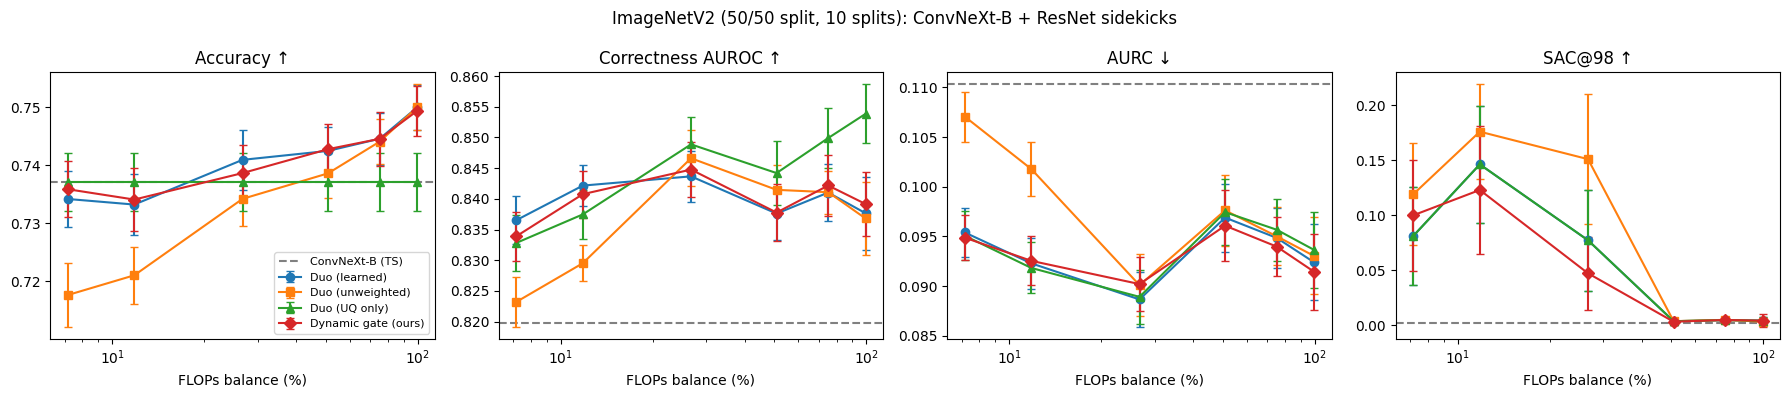

In [15]:
PLOT = [("acc", "Accuracy ↑"), ("auroc", "Correctness AUROC ↑"), ("aurc", "AURC ↓"), ("sac", f"SAC@{int(SAC_TARGET*100)} ↑")]
STYLE = {"duo learned (paper conf)": ("C0", "o", "Duo (learned)"),
         "duo unweighted":           ("C1", "s", "Duo (unweighted)"),
         "duo UQ-only":              ("C2", "^", "Duo (UQ only)"),
         "dynamic gate":             ("C3", "D", "Dynamic gate (ours)")}
mean = R.groupby(["sidekick", "flop_balance", "method"])[[m for m, _ in PLOT]].agg(["mean", "std"]).reset_index()
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (m, title) in zip(axes, PLOT):
    base = mean[mean.method == "base (TS)"][(m, "mean")].mean()
    ax.axhline(base, color="grey", ls="--", label="ConvNeXt-B (TS)")
    for meth, (c, mk, lab) in STYLE.items():
        d = mean[mean.method == meth].sort_values("flop_balance")
        ax.errorbar(d.flop_balance * 100, d[(m, "mean")], yerr=d[(m, "std")], color=c, marker=mk, label=lab, capsize=3)
    ax.set_xscale("log"); ax.set_xlabel("FLOPs balance (%)"); ax.set_title(title)
axes[0].legend(fontsize=8)
plt.suptitle(f"ImageNetV2 (50/50 split, {N_SPLITS} splits): ConvNeXt-B + ResNet sidekicks")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "duo_vs_flops_imagenetv2.png"), dpi=150); plt.show()

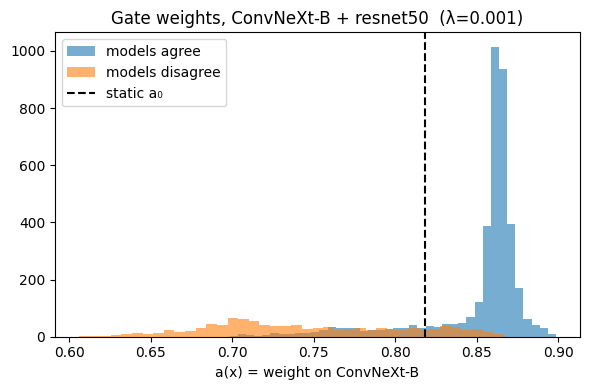

β (gap_large, gap_small, agree): [-0.117  0.341  0.124]


In [16]:
# --- Where does the gate put weight? ---------------------------------------------
side = "resnet50" if "resnet50" in SIDEKICKS else SIDEKICKS[0]
Ll, Ls = LOGITS[LARGE], LOGITS[side]
rng = np.random.default_rng(SEED); va, te = stratified_split(Y, rng)
_, ps = evaluate_static(Ll, Ls, Y, va, te)
phi_raw = gate_features(Ll, Ls); mu, sd = phi_raw[va].mean(0), phi_raw[va].std(0) + 1e-6; phi = (phi_raw - mu) / sd
lam = choose_lambda(Ll[va], Ls[va], phi[va], Y[va], rng)
g = fit_gate(Ll[va], Ls[va], phi[va], Y[va], (ps["w_large"], ps["w_small"]), lam)
_, a = gate_logits(Ll[te], Ls[te], phi[te], g)
agree = phi_raw[te, 2] == 1
plt.figure(figsize=(6, 4))
plt.hist(a[agree], bins=40, alpha=.6, label="models agree"); plt.hist(a[~agree], bins=40, alpha=.6, label="models disagree")
plt.axvline(ps["w_large"] / (ps["w_large"] + ps["w_small"]), color="k", ls="--", label="static a₀")
plt.xlabel("a(x) = weight on ConvNeXt-B"); plt.legend(); plt.title(f"Gate weights, ConvNeXt-B + {side}  (λ={lam})")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, f"gate_weights_{side}.png"), dpi=150); plt.show()
print("β (gap_large, gap_small, agree):", g["beta"].round(3))

## 9. Results summary (N_SPLITS = 10, test halves, mean ± std)

Base model: ConvNeXt-B, 73.7% accuracy on ImageNetV2. Percentages below are absolute (e.g. AURC 11.03%).

- **Learned Duo vs temperature-scaled base:** AURC improves from 11.03% to 8.87–9.69% for *every* sidekick, including ResNet-10T at 7% FLOP balance (9.54%), in 10/10 splits each. NLL improves from 1.215 to 1.12–1.17, and AUROC from 81.98% to 83.65–84.46%.
- **Accuracy:** −0.3 / −0.4 points with ResNet-10T / ResNet-18 (within the split-to-split std of ~0.5), and +0.4 to +1.3 points from ResNet-50 upward.
- **UQ-only:** its AURC is within about 0.05 points of the full learned Duo, and its AUROC is equal or higher. So the gain comes mainly from better confidence ranking, not from changed predictions.
- **Unweighted vs learned:** with small sidekicks the 50/50 Duo is worse than the base model (ResNet-10T: 71.76% accuracy, AURC 10.71%). The two converge as the sidekick approaches the base's size.
- **Learned weights:** w_large / w_small move from 0.95 / 0.25 (ResNet-10T) to 0.62 / 0.59 (ResNet-200D), so more weight goes to the base model when the sidekick is small.
- **Paper vs released confidence:** at most 0.35 points of AUROC and 0.07 points of AURC difference, because the Duo and the base model usually predict the same class.
- **SAC@98:** the base model reaches 98% accuracy only on its top 0.21% of test images. Across splits the std is 3–6 points, so the metric is not informative at this accuracy level and test size.
- **Sidekicks alone** rank their own errors better (AUROC 84.0–86.0%) than ConvNeXt-B (82.0%), despite lower accuracy.
- **Dynamic gate vs static Duo:** NLL is lower in 10/10 splits for every sidekick, but only by 0.004–0.006. AURC improves by 0.05–0.10 points for ResNet-10T/101/152/200D and worsens by 0.03 / 0.16 points for ResNet-18 / 50. The confidence-only ablation gives nearly the same numbers, so any effect is in the confidence, not the predictions. The gate weight a(x) varies little across images (std ≈ 0.06–0.07).
